**Project Title:** E-commerce Delivery Analytics

**Dataset Source:** Kaggle

**Project File Name:** `Ecommerce_Delivery_Analytics.ipynb`

**Dataset Requirements:**
- Total Rows: 100000
- Total Columns: 11
- Format: CSV

**Column Names:**
1. Order ID
2. Customer ID
3. Platform
4. Order Date & Time
5. Delivery Time (Minutes)
6. Product Category
7. Order Value (INR)
8. Customer Feedback
9. Service Rating
10. Delivery Delay
11. Refund Requested

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:


df = pd.read_csv("Ecommerce_Delivery_Analytics_New.csv")


In [3]:
#first 5 record
df.head()

,Order ID,Customer ID,Platform,Order Date & Time,Delivery Time (Minutes),Product Category,Order Value (INR),Customer Feedback,Service Rating,Delivery Delay,Refund Requested
0,ORD000001,CUST2824,JioMart,19:29.5,30,Fruits & Vegetables,382,"Fast delivery, great service!",5,No,No
1,ORD000002,CUST1409,Blinkit,54:29.5,16,Dairy,279,Quick and reliable!,5,No,No
2,ORD000003,CUST5506,JioMart,21:29.5,25,Beverages,599,Items missing from order.,2,No,Yes
3,ORD000004,CUST5012,JioMart,19:29.5,42,Beverages,946,Items missing from order.,2,Yes,Yes
4,ORD000005,CUST4657,Blinkit,49:29.5,30,Beverages,334,"Fast delivery, great service!",5,No,No


In [4]:
#last record 5 record
df.tail()

,Order ID,Customer ID,Platform,Order Date & Time,Delivery Time (Minutes),Product Category,Order Value (INR),Customer Feedback,Service Rating,Delivery Delay,Refund Requested
99995,ORD099996,CUST5324,JioMart,49:29.5,24,Dairy,289,Packaging could be better.,3,No,No
99996,ORD099997,CUST1677,JioMart,18:29.5,19,Snacks,322,Good quality products.,4,No,No
99997,ORD099998,CUST8198,JioMart,27:29.5,41,Dairy,135,"Fast delivery, great service!",5,Yes,No
99998,ORD099999,CUST9975,JioMart,14:29.5,31,Grocery,973,Quick and reliable!,5,No,No
99999,ORD100000,CUST3748,JioMart,41:29.5,34,Fruits & Vegetables,453,Packaging could be better.,3,No,No


In [5]:
#data set details
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   Order ID                 100000 non-null  object
 1   Customer ID              100000 non-null  object
 2   Platform                 100000 non-null  object
 3   Order Date & Time        100000 non-null  object
 4   Delivery Time (Minutes)  100000 non-null  int64 
 5   Product Category         100000 non-null  object
 6   Order Value (INR)        100000 non-null  int64 
 7   Customer Feedback        100000 non-null  object
 8   Service Rating           100000 non-null  int64 
 9   Delivery Delay           100000 non-null  object
 10  Refund Requested         100000 non-null  object
dtypes: int64(3), object(8)
memory usage: 8.4+ MB


In [6]:
df.isnull().sum()

Order ID                   0
Customer ID                0
Platform                   0
Order Date & Time          0
Delivery Time (Minutes)    0
Product Category           0
Order Value (INR)          0
Customer Feedback          0
Service Rating             0
Delivery Delay             0
Refund Requested           0
dtype: int64

In [7]:
def clean_time(time_str):
    """
    This function cleans invalid time strings by replacing hours greater than 23 with 23.
    """
    if len(time_str) > 0:
        try:
            # Split the time string into components
            parts = time_str.split(':')

            # If the hour is greater than 23, replace it with 23
            if int(parts[0]) > 23:
                parts[0] = '23'

            # Rejoin the components
            cleaned_time_str = ':'.join(parts)
            return cleaned_time_str

        except (ValueError, IndexError):
            # Handle cases where the time string is not in the expected format
            return time_str
    else:
        return time_str  # Return as is for empty strings


# Apply the cleaning function to the 'Order Date & Time' column
df['Order Date & Time'] = df['Order Date & Time'].apply(clean_time)

# Convert the cleaned column to datetime objects
df['Order Date & Time'] = pd.to_datetime(
    df['Order Date & Time'], errors='coerce'
)

C:\Users\manda\AppData\Local\Temp\ipykernel_16536\1682544890.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Order Date & Time'] = pd.to_datetime(


In [8]:
df


,Order ID,Customer ID,Platform,Order Date & Time,Delivery Time (Minutes),Product Category,Order Value (INR),Customer Feedback,Service Rating,Delivery Delay,Refund Requested
0,ORD000001,CUST2824,JioMart,2026-10-27 19:29:30,30,Fruits & Vegetables,382,"Fast delivery, great service!",5,No,No
1,ORD000002,CUST1409,Blinkit,2026-10-27 23:29:30,16,Dairy,279,Quick and reliable!,5,No,No
2,ORD000003,CUST5506,JioMart,2026-10-27 21:29:30,25,Beverages,599,Items missing from order.,2,No,Yes
3,ORD000004,CUST5012,JioMart,2026-10-27 19:29:30,42,Beverages,946,Items missing from order.,2,Yes,Yes
4,ORD000005,CUST4657,Blinkit,2026-10-27 23:29:30,30,Beverages,334,"Fast delivery, great service!",5,No,No
...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST5324,JioMart,2026-10-27 23:29:30,24,Dairy,289,Packaging could be better.,3,No,No
99996,ORD099997,CUST1677,JioMart,2026-10-27 18:29:30,19,Snacks,322,Good quality products.,4,No,No
99997,ORD099998,CUST8198,JioMart,2026-10-27 23:29:30,41,Dairy,135,"Fast delivery, great service!",5,Yes,No
99998,ORD099999,CUST9975,JioMart,2026-10-27 14:29:30,31,Grocery,973,Quick and reliable!,5,No,No


In [10]:
df.columns

Index(['Order ID', 'Customer ID', 'Platform', 'Order Date & Time',
       'Delivery Time (Minutes)', 'Product Category', 'Order Value (INR)',
       'Customer Feedback', 'Service Rating', 'Delivery Delay',
       'Refund Requested'],
      dtype='object')

In [9]:
df.describe()

,Order Date & Time,Delivery Time (Minutes),Order Value (INR),Service Rating
count,100000,100000.000000,100000.000000,100000.000000
mean,2026-10-27 18:54:08.375998976,29.536140,590.994400,3.240790
min,2026-10-27 00:29:30,5.000000,50.000000,1.000000
25%,2026-10-27 15:29:30,23.000000,283.000000,2.000000
50%,2026-10-27 23:29:30,30.000000,481.000000,3.000000
75%,2026-10-27 23:29:30,36.000000,770.000000,5.000000
max,2026-10-27 23:29:30,76.000000,2000.000000,5.000000
std,NaN,9.958933,417.409058,1.575962


In [11]:
df['Order Value (INR)'].describe()

count    100000.000000
mean        590.994400
std         417.409058
min          50.000000
25%         283.000000
50%         481.000000
75%         770.000000
max        2000.000000
Name: Order Value (INR), dtype: float64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df['Platform'].value_counts()

Platform
Swiggy Instamart    33449
Blinkit             33424
JioMart             33127
Name: count, dtype: int64

In [14]:
df[['Product Category', 'Platform', 'Service Rating']].value_counts()

Product Category     Platform          Service Rating
Personal Care        Swiggy Instamart  5                 2240
Beverages            Swiggy Instamart  5                 2217
Fruits & Vegetables  JioMart           5                 2211
Dairy                Swiggy Instamart  5                 2190
                     JioMart           5                 2184
                                                         ... 
Fruits & Vegetables  JioMart           3                  408
Personal Care        Blinkit           3                  406
Grocery              JioMart           4                  404
Beverages            JioMart           3                  397
                     Swiggy Instamart  4                  394
Name: count, Length: 90, dtype: int64

In [15]:
df.groupby('Product Category')['Order Value (INR)'].sum().sort_values(ascending=False)

Product Category
Personal Care          17395601
Grocery                14194055
Beverages               9086669
Dairy                   7610522
Fruits & Vegetables     6246517
Snacks                  4566076
Name: Order Value (INR), dtype: int64

In [16]:
df.groupby(['Product Category', 'Platform'])['Order Value (INR)'].sum().sort_values(ascending=True)

Product Category     Platform        
Snacks               JioMart             1520261
                     Swiggy Instamart    1522702
                     Blinkit             1523113
Fruits & Vegetables  Swiggy Instamart    2073368
                     JioMart             2075237
                     Blinkit             2097912
Dairy                JioMart             2516935
                     Swiggy Instamart    2545982
                     Blinkit             2547605
Beverages            JioMart             2967101
                     Swiggy Instamart    3055655
                     Blinkit             3063913
Grocery              Swiggy Instamart    4716086
                     Blinkit             4731502
                     JioMart             4746467
Personal Care        JioMart             5736371
                     Blinkit             5741039
                     Swiggy Instamart    5918191
Name: Order Value (INR), dtype: int64

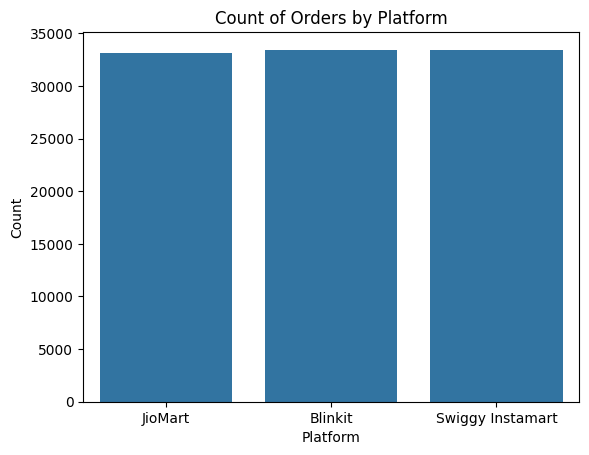

In [17]:
import seaborn as sns


sns.countplot(x='Platform', data=df)

plt.xlabel("Platform")
plt.ylabel("Count")
plt.title("Count of Orders by Platform")

plt.show()

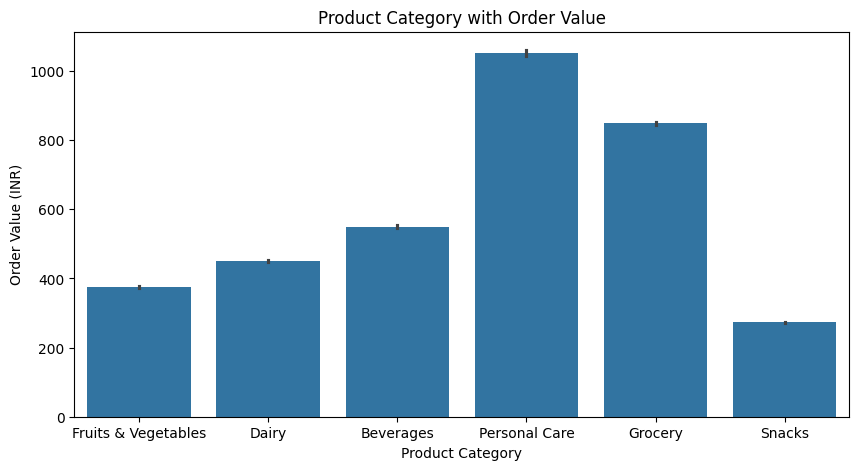

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(x='Product Category', y='Order Value (INR)', data=df)

plt.xlabel("Product Category")
plt.ylabel("Order Value (INR)")
plt.title("Product Category with Order Value")

plt.show()

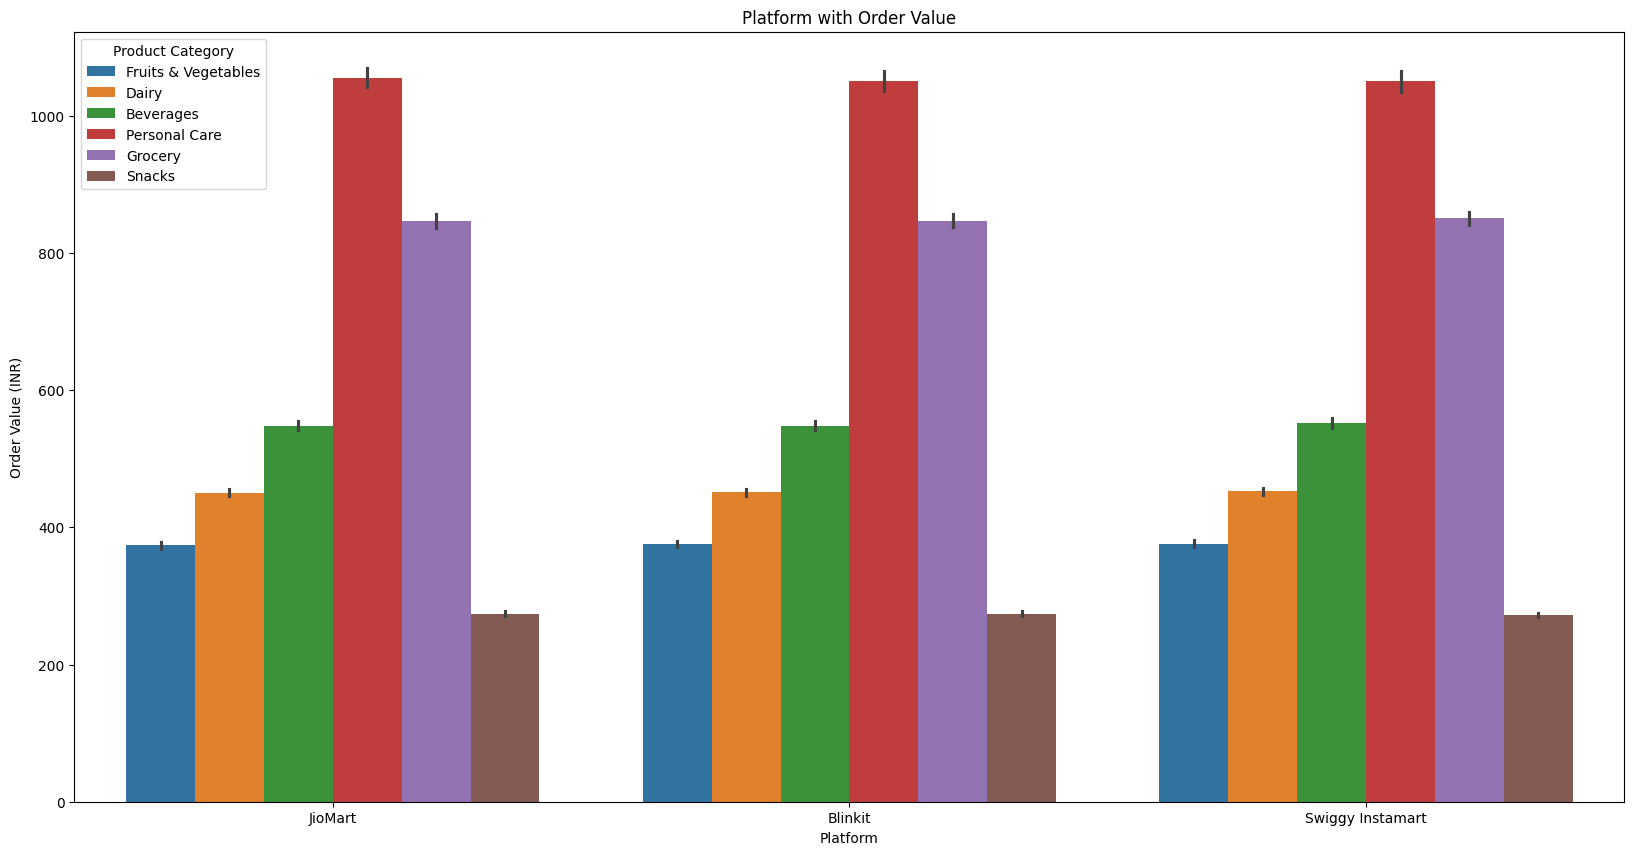

In [19]:
plt.figure(figsize=(20, 10))

sns.barplot(
    x='Platform',
    y='Order Value (INR)',
    data=df,
    hue='Product Category'
)

plt.xlabel("Platform")
plt.ylabel("Order Value (INR)")
plt.title("Platform with Order Value")

plt.show()

In [20]:
df.rename(columns={'Order value(INR)': 'Order_value'}, inplace=True)
df

,Order ID,Customer ID,Platform,Order Date & Time,Delivery Time (Minutes),Product Category,Order Value (INR),Customer Feedback,Service Rating,Delivery Delay,Refund Requested
0,ORD000001,CUST2824,JioMart,2026-10-27 19:29:30,30,Fruits & Vegetables,382,"Fast delivery, great service!",5,No,No
1,ORD000002,CUST1409,Blinkit,2026-10-27 23:29:30,16,Dairy,279,Quick and reliable!,5,No,No
2,ORD000003,CUST5506,JioMart,2026-10-27 21:29:30,25,Beverages,599,Items missing from order.,2,No,Yes
3,ORD000004,CUST5012,JioMart,2026-10-27 19:29:30,42,Beverages,946,Items missing from order.,2,Yes,Yes
4,ORD000005,CUST4657,Blinkit,2026-10-27 23:29:30,30,Beverages,334,"Fast delivery, great service!",5,No,No
...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST5324,JioMart,2026-10-27 23:29:30,24,Dairy,289,Packaging could be better.,3,No,No
99996,ORD099997,CUST1677,JioMart,2026-10-27 18:29:30,19,Snacks,322,Good quality products.,4,No,No
99997,ORD099998,CUST8198,JioMart,2026-10-27 23:29:30,41,Dairy,135,"Fast delivery, great service!",5,Yes,No
99998,ORD099999,CUST9975,JioMart,2026-10-27 14:29:30,31,Grocery,973,Quick and reliable!,5,No,No


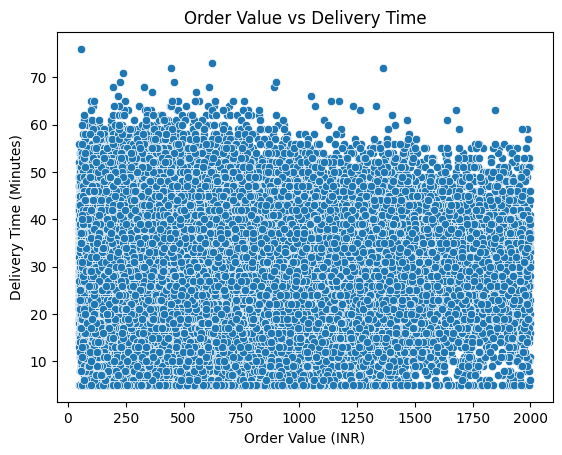

In [21]:
sns.scatterplot(
    x='Order Value (INR)',
    y='Delivery Time (Minutes)',
    data=df
)

plt.xlabel("Order Value (INR)")
plt.ylabel("Delivery Time (Minutes)")
plt.title("Order Value vs Delivery Time")
plt.show()

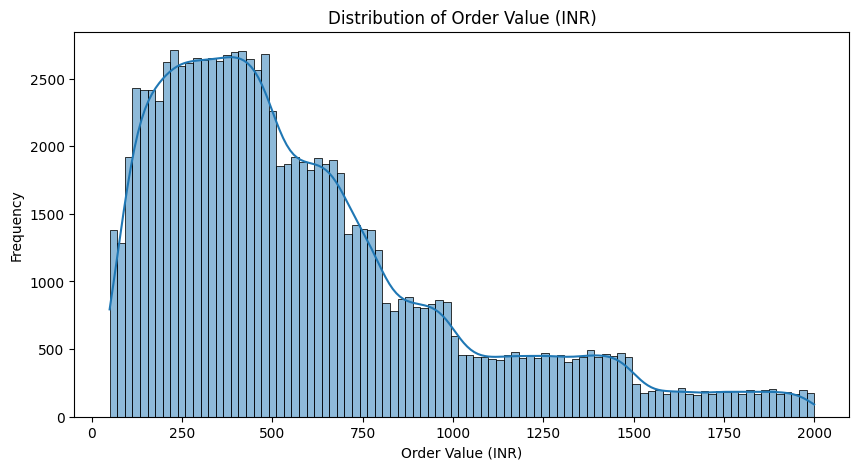

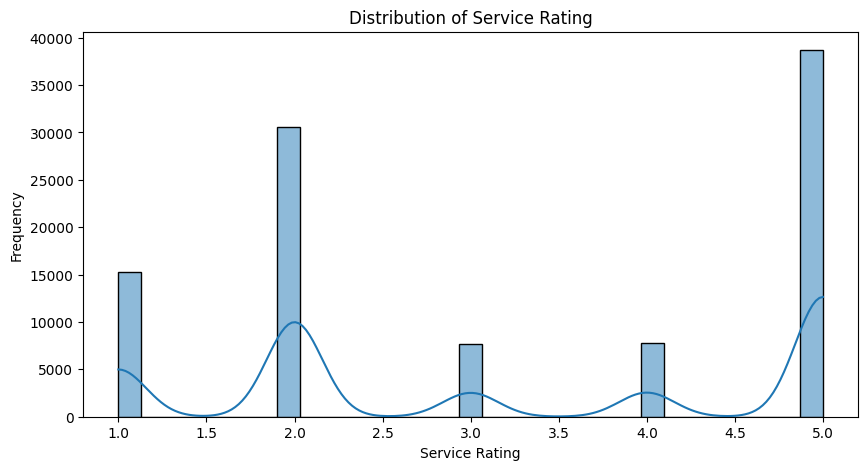

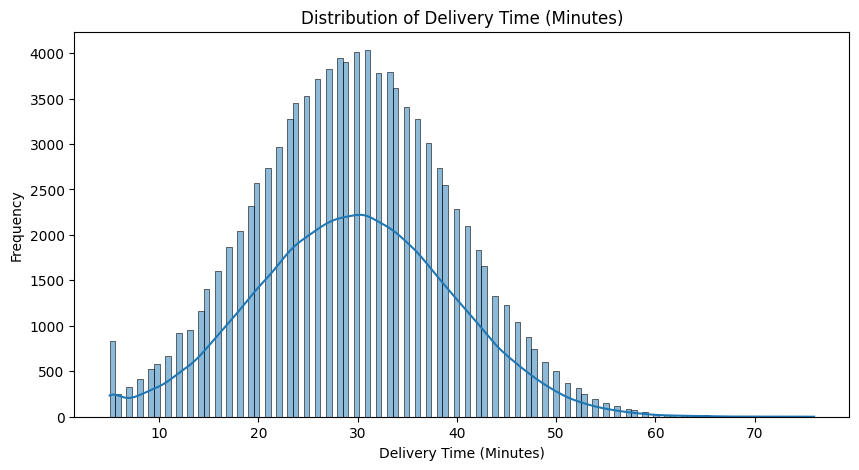

In [22]:
dist_plot = ['Order Value (INR)', 'Service Rating', 'Delivery Time (Minutes)']

for i in dist_plot:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[i], kde=True)
    plt.title(f'Distribution of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.show()

In [23]:
corr_list = ['Order Value (INR)', 'Service Rating', 'Delivery Time (Minutes)']

df[corr_list].corr()

,Order Value (INR),Service Rating,Delivery Time (Minutes)
Order Value (INR),1.000000,-0.002689,0.007225
Service Rating,-0.002689,1.000000,0.000136
Delivery Time (Minutes),0.007225,0.000136,1.000000


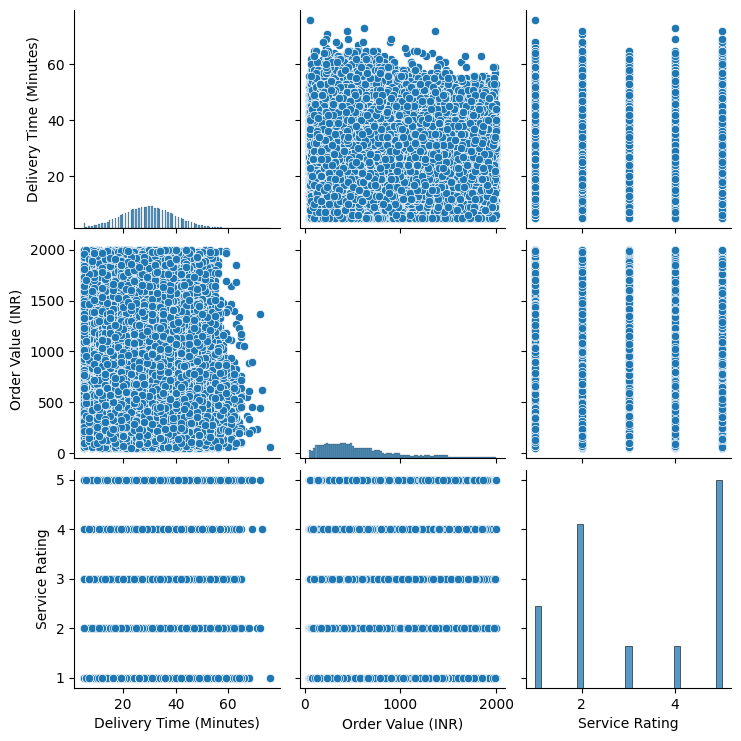

In [24]:
sns.pairplot(df)

In [25]:
df['Customer Feedback'].value_counts().sort_values(ascending=False)

Customer Feedback
Easy to order, loved it!                      7791
Good quality products.                        7789
Excellent experience!                         7784
Very satisfied with the service.              7740
Wrong item delivered.                         7738
Items missing from order.                     7737
Fast delivery, great service!                 7715
Packaging could be better.                    7704
Quick and reliable!                           7658
Delivery person was rude.                     7643
Very late delivery, not happy.                7592
Not fresh, disappointed.                      7580
Horrible experience, never ordering again.    7529
Name: count, dtype: int64

<Axes: xlabel='Customer Feedback', ylabel='count'>

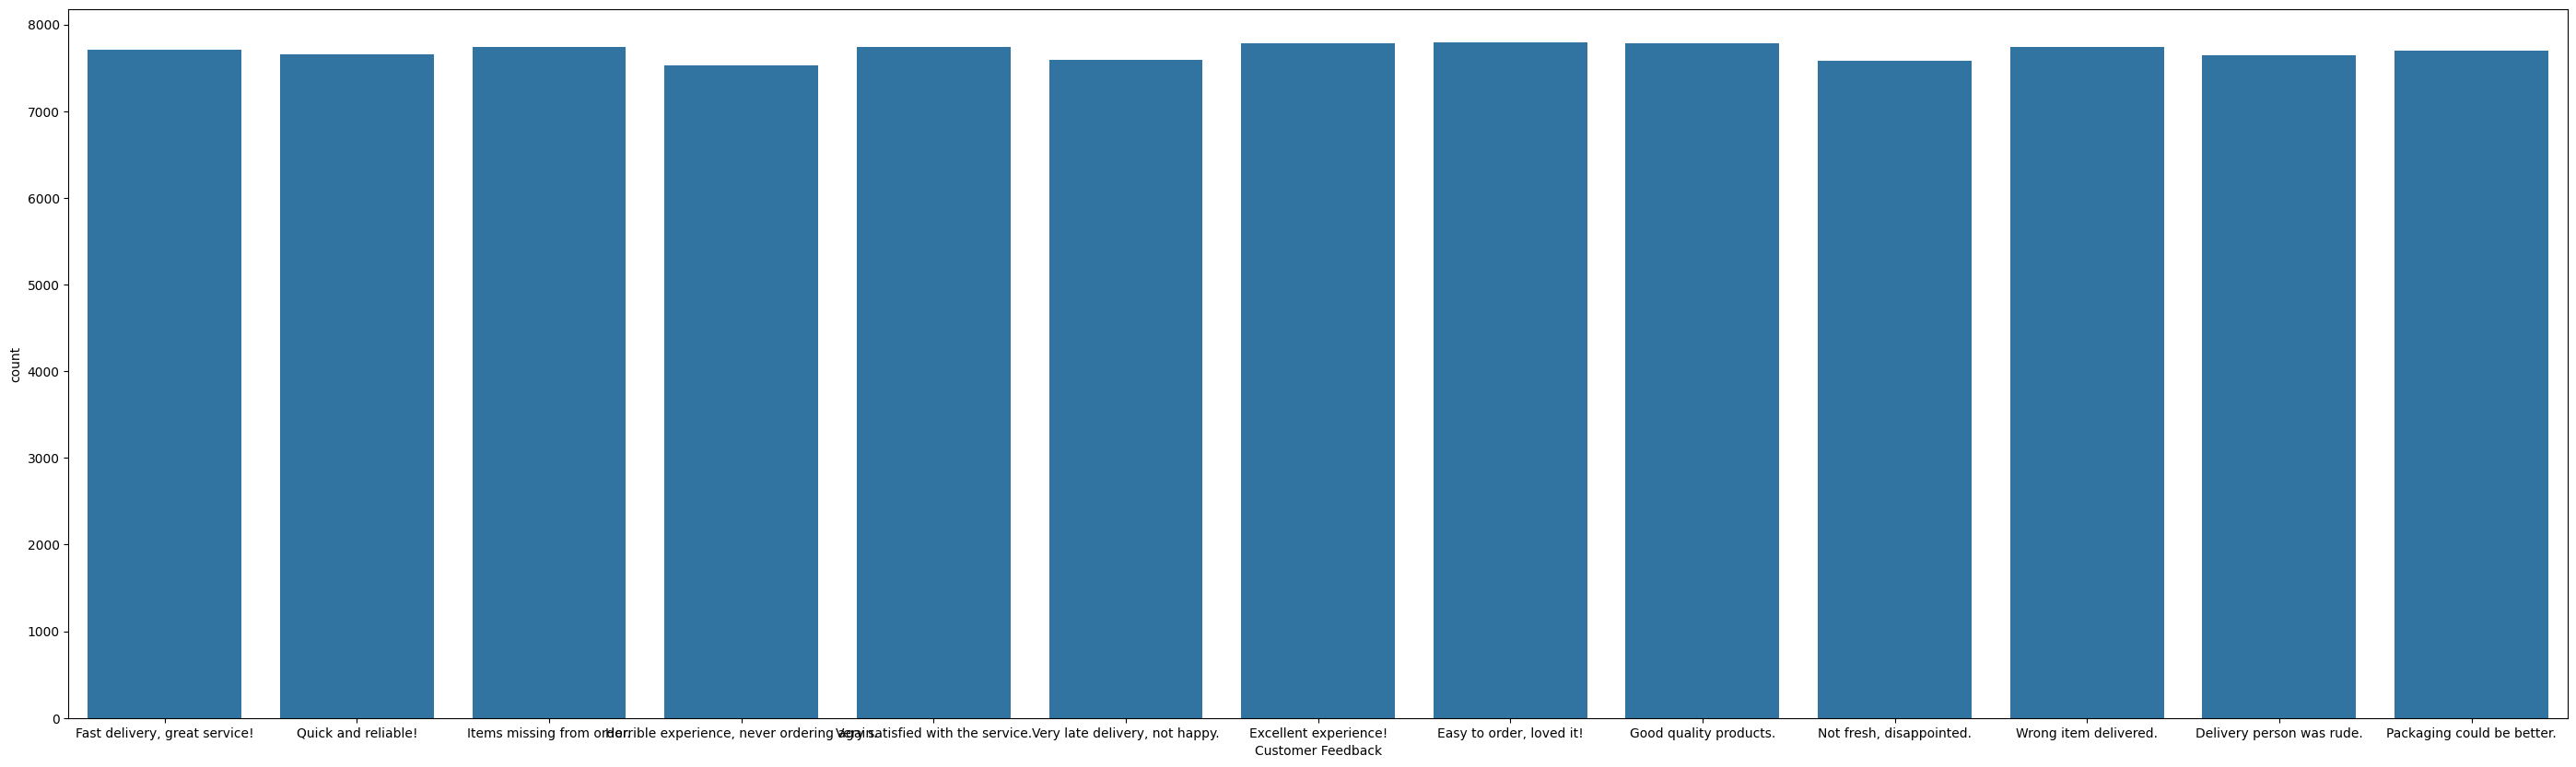

In [26]:
plt.figure(figsize=(35,10))

sns.countplot(x='Customer Feedback', data=df)


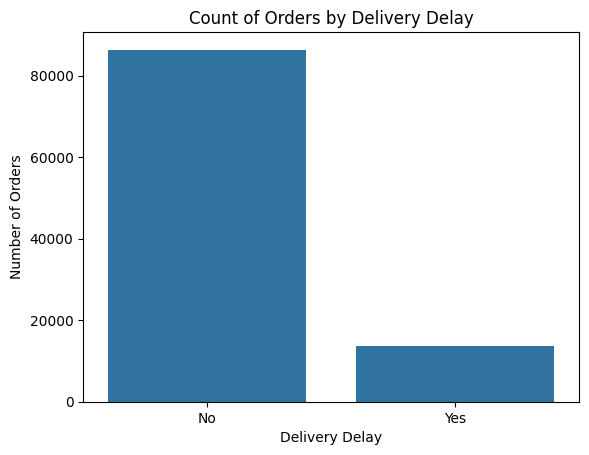

In [27]:
sns.countplot(x='Delivery Delay', data=df)

plt.xlabel("Delivery Delay")
plt.ylabel("Number of Orders")
plt.title("Count of Orders by Delivery Delay")

plt.show()

In [28]:

df.groupby('Delivery Delay')['Order Value (INR)'].sum()

Delivery Delay
No     50980613
Yes     8118827
Name: Order Value (INR), dtype: int64

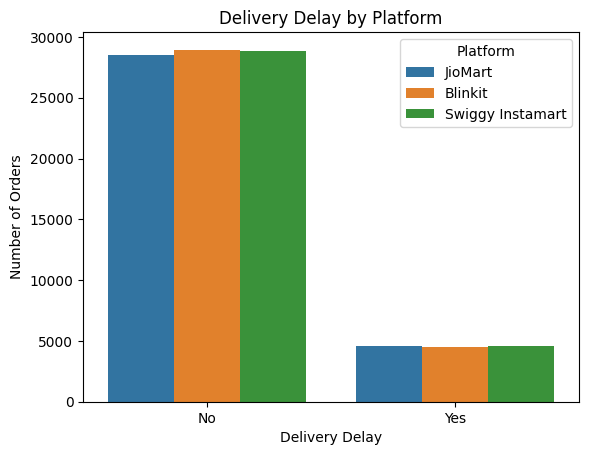

In [29]:
sns.countplot(x='Delivery Delay', hue='Platform', data=df)

plt.xlabel("Delivery Delay")
plt.ylabel("Number of Orders")
plt.title("Delivery Delay by Platform")
plt.show()

In [30]:
df.groupby('Refund Requested')['Service Rating'].sum()

Refund Requested
No     247708
Yes     76371
Name: Service Rating, dtype: int64

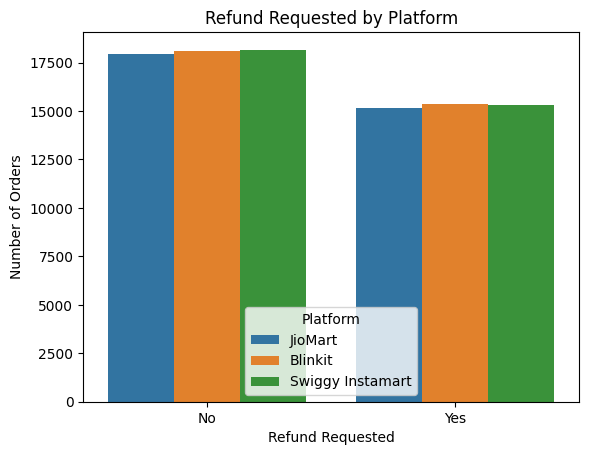

In [31]:
sns.countplot(x='Refund Requested', hue='Platform', data=df)

plt.xlabel("Refund Requested")
plt.ylabel("Number of Orders")
plt.title("Refund Requested by Platform")
plt.show()

In [32]:
df.groupby(['Refund Requested', 'Platform'])['Service Rating'].sum()

Refund Requested  Platform        
No                Blinkit             82523
                  JioMart             82146
                  Swiggy Instamart    83039
Yes               Blinkit             25565
                  JioMart             25356
                  Swiggy Instamart    25450
Name: Service Rating, dtype: int64

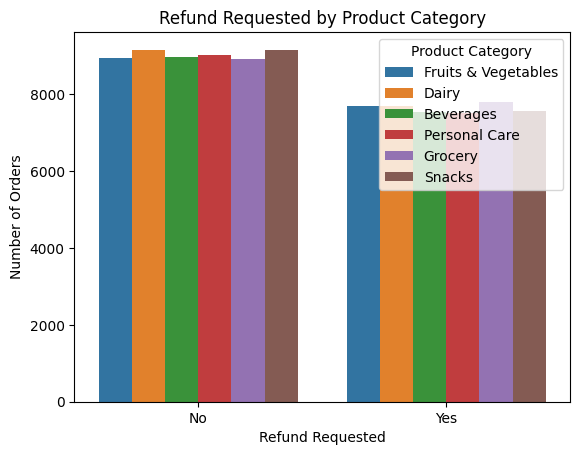

In [33]:
sns.countplot(x='Refund Requested', hue='Product Category', data=df)

plt.xlabel("Refund Requested")
plt.ylabel("Number of Orders")
plt.title("Refund Requested by Product Category")
plt.show()